# REINFORCE and Baselines

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Saved means and standard deviations summarize the training reward arrays, not a separate evaluation set: no causality 58.7 ± 28.5, no baseline 283.8 ± 172.2, constant baseline 284.1 ± 190.0, learned baseline 343.3 ± 186.6. These do not establish a universal ranking or uncertainty across independent seeds.


# HW2: Policy Gradiant
> - Full Name: **[behrad mazaheri]**
> - Student ID: **[[student ID removed]]**


## Objective

In this notebook, you will implement the **REINFORCE policy gradient algorithm** (also known as Monte Carlo policy gradient) to train an agent on the **CartPole‑v1** environment from OpenAI Gym. REINFORCE is a fundamental policy‑based reinforcement learning method that directly optimises the policy parameters by performing stochastic gradient ascent on the expected cumulative reward. However, the standard REINFORCE update is known to suffer from **high variance**, which can lead to slow convergence and unstable learning curves.

## Variance Reduction Techniques

To address this issue, this notebook further explores three variance‑reduction strategies that are commonly applied to the REINFORCE algorithm. You will implement each of them and empirically analyse their effects on learning speed, stability, and final performance. The techniques are:

1. **The causality trick (reward‑to‑go)**  
   Instead of using the full return from the start of an episode, this method replaces the cumulative reward with the sum of future rewards from each time step onward. By ignoring rewards obtained before the current action, the gradient estimator retains the same unbiasedness while significantly reducing variance.

2. **Constant baseline**  
   A fixed scalar baseline is subtracted from the return (or the reward‑to‑go) in the policy gradient estimate. Subtracting a constant does not introduce bias, but a well‑chosen constant (e.g., the average return over recent episodes) can reduce variance by centring the advantage estimates.

3. **Learned baseline (value function baseline)**  
   A more sophisticated approach that uses a separate function approximator (typically a neural network) to estimate the state‑value function. This learned baseline adapts during training and provides a state‑dependent offset. The advantage estimate then often yields the lowest variance among these three methods, at the cost of adding a second learning process.

## Implementation and Analysis

You will implement the core REINFORCE update, then systematically extend it with each of the three variance‑reduction techniques. For every variant, you will run multiple training episodes, plot the smoothed episode returns, and compare convergence behaviour. The notebook will guide you through:

- Setting up the CartPole‑v1 environment (discrete action space, continuous observation space).
- Defining a policy network (e.g., a shallow multi‑layer perceptron) with a softmax output layer.
- Writing the training loop that collects episodes, computes policy gradients, and updates the policy.
- Modifying the advantage estimator to incorporate causality and baseline subtractions.
- Training and evaluating each variant with identical random seeds for fair comparison.

By the end of this notebook, you will gain hands‑on insight into how different variance‑reduction mechanisms affect the practical performance of Monte Carlo policy gradient methods.

# Setup

All required packages are pre-installed if using Google Colab.


Import the following libraries.

In [3]:
# Imports
import numpy as np
if not hasattr(np, 'bool8'):
    np.bool8 = np.bool_

import torch
import torch.nn as nn
import torch.optim as optim
from torch.distributions import Categorical
import gym
import matplotlib
import matplotlib.pyplot as plt
import base64
import imageio
import IPython
import logging
import warnings

# Disable warnings
logging.getLogger().setLevel(logging.ERROR)
warnings.filterwarnings('ignore', category=DeprecationWarning)

# DEVICE
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


device(type='cuda')

Note: While we check for CUDA availability, using a GPU is not strictly necessary for this assignment. The neural networks used here are small, and the majority of training time is spent running episodes in the environment (which occurs on the CPU), rather than performing backpropagation updates.

Set a fix seed to be able to compare results

In [4]:
import random

def set_seed(seed=333):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Optional: more deterministic behavior
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
set_seed(333)

Configure Matplotlib for Interactive and XKCD-Style Plots

In [5]:
# Set up matplotlib
is_ipython = 'inline' in matplotlib.get_backend()
if is_ipython:
    from IPython import display
plt.ion()
plt.xkcd(scale=1, length=100, randomness=2)
matplotlib.rcParams['figure.figsize'] = (12, 6)

Record and Embed Simulation Videos in Jupyter Notebook

<b>embed_mp4:</b> Converts an MP4 video into a base64-encoded HTML tag for display in Jupyter Notebook.
<br>
<b>record_simulation:</b> Runs a policy in the environment, records the simulation, and saves it as an MP4 video.

In [6]:
def embed_mp4(filename):
    video = open(filename,'rb').read()
    b64 = base64.b64encode(video)
    tag = '''
    <video width="640" height="480" controls>
    <source src="data:video/mp4;base64,{0}" type="video/mp4">
    Your browser does not support the video tag.
    </video>'''.format(b64.decode())
#     return IPython.display.HTML(tag)

# def record_simulation(env, policy_net, filename, episodes=1, fps=30):
#     filename = filename + ".mp4"
#     with imageio.get_writer(filename, fps=fps) as video:
#         for _ in range(episodes):
#             state = env.reset()
#             frame = env.render()  # Capture the first frame
#             video.append_data(frame[0])

#             done = False
#             while not done:
#                 state_tensor = torch.FloatTensor(state).to(DEVICE)
#                 action = torch.argmax(policy_net(state_tensor)).item()
#                 state, _, terminated, truncated, _ = env.step(action)

#                 frame = env.render()  # Capture the frame after taking the action
#                 video.append_data(frame[0])

#                 done = terminated or truncated
#     return embed_mp4(filename)
def record_simulation(env, policy_net, filename, episodes=1, fps=30):
    filename = filename + ".mp4"

    with imageio.get_writer(filename, fps=fps) as video:
        for _ in range(episodes):

            reset_result = env.reset()
            if isinstance(reset_result, tuple):
                state, _ = reset_result
            else:
                state = reset_result

            done = False

            while not done:
                frame = env.render()
                video.append_data(frame)

                state_tensor = torch.FloatTensor(state).to(DEVICE)

                with torch.no_grad():
                    action_probs = policy_net(state_tensor)
                    action = torch.argmax(action_probs).item()

                step_result = env.step(action)

                if len(step_result) == 5:
                    state, reward, terminated, truncated, _ = step_result
                    done = terminated or truncated
                else:
                    state, reward, done, _ = step_result

    return embed_mp4(filename)

# Explore the environment

Initialize CartPole Environment and Display State & Action Spaces

In [7]:
# Create the CartPole environment
env = gym.make("CartPole-v1")

# Print observation and action space
print("Observation Space:", env.observation_space)
print("Action Space:", env.action_space)

Observation Space: Box([-4.8000002e+00 -3.4028235e+38 -4.1887903e-01 -3.4028235e+38], [4.8000002e+00 3.4028235e+38 4.1887903e-01 3.4028235e+38], (4,), float32)
Action Space: Discrete(2)


**Question**

How are the observation and action spaces defined in the CartPole environment?

**Answer:**
The CartPole observation space is defined as Box(..., shape=(4,), dtype=float32). It represents four continuous state variables: cart position, cart velocity, pole angle, and pole angular velocity. The action space is Discrete(2), so there are two possible actions. Action 0 applies force to the left, and action 1 applies force to the right.

Define a Random Policy for Action Selection  

In [8]:
class RandomPolicy(object):

    def __init__(self, action_space_n):
        self.action_space_n = action_space_n

    def __call__(self, state):
        action_values = torch.rand(self.action_space_n)
        return action_values

Visualize the random policy.

In [9]:
import numpy as np

random_policy = RandomPolicy(env.action_space.n)

record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), random_policy, "Video_CartPole_random_policy")

# Agent with REINFORCE: Normal vs Causality vs Simple Baseline vs Learned Baseline


### Policy Network Definition

To define a neural network that represents the agent’s policy for selecting actions.

The policy network takes the environment’s state as input and outputs a probability distribution over possible actions.

In [10]:
class PolicyNetwork(nn.Module):
    def __init__(self, input_dim, output_dim):
        super(PolicyNetwork, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, output_dim),
            nn.Softmax(dim=-1)
        )

    def forward(self, state):
        return self.net(state)

### REINFORCE without Causality

#### 1. The Objective Function
In Policy Gradient methods, we aim to maximize the expected return:
$$J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta} [G(\tau)]$$
where $\tau = (s_0, a_0, s_1, a_1, \dots, s_T)$ is a trajectory sampled from the policy $\pi_\theta$, and $G(\tau)$ is the total discounted return.

#### 2. The Policy Gradient Theorem
The gradient of the objective function is given by:
$$\nabla_\theta J(\theta) = \mathbb{E}_{\tau \sim \pi_\theta} \left[ \left( \sum_{t=0}^{T} \nabla_\theta \log \pi_\theta(a_t | s_t) \right) G(\tau) \right]$$

#### 3. Full Return vs. Reward-to-go
In the code implementation `reinforce_no_causality`, we use the **Full Return** $G_0$ for every action in the trajectory:
- **Definition of $G_0$**: $G_0 = \sum_{k=0}^{T} \gamma^k R_k$
- **Update Rule**: $\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_\theta \log \pi_\theta(a_t | s_t) G_0$

#### Definitions:
- **$\pi_\theta(a_t | s_t)$**: The probability of taking action $a_t$ given state $s_t$ under parameters $\theta$.
- **$\nabla_\theta \log \pi_\theta(a_t | s_t)$**: The 'score function' or direction in parameter space that increases the probability of action $a_t$.
- **$G_0$**: The total scalar reward of the entire episode. If the episode was good, $G_0$ is high, and we push the probabilities of *all* actions taken in that episode 'up' equally.


In [11]:
def reinforce_no_causality(env, policy_net, optimizer, num_episodes=1000, gamma=0.99):
    rewards_per_episode = []

    for episode in range(num_episodes):
        reset_result = env.reset()
        if isinstance(reset_result, tuple):
            state, _ = reset_result
        else:
            state = reset_result

        log_probs = []
        rewards = []

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).to(DEVICE)

            action_probs = policy_net(state_tensor)

            dist = torch.distributions.Categorical(action_probs)
            action = dist.sample()
            log_prob = dist.log_prob(action)

            step_result = env.step(action.item())

            if len(step_result) == 5:
                next_state, reward, terminated, truncated, _ = step_result
                done = terminated or truncated
            else:
                next_state, reward, done, _ = step_result

            log_probs.append(log_prob)
            rewards.append(reward)

            state = next_state

        G0 = 0
        for t, reward in enumerate(rewards):
            G0 += (gamma ** t) * reward

        loss = 0
        for log_prob in log_probs:
            loss += -log_prob * G0

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_reward = sum(rewards)
        rewards_per_episode.append(total_reward)

    return rewards_per_episode

**Question:**

Why does this method has high variance?



**Answer:**This method has high variance because it assigns the same full-episode return G0 to every action in the trajectory. Therefore, each action is credited or blamed for rewards that may not be causally related to it, including rewards that occurred before that action. This makes the gradient estimate noisy. Although the estimator is unbiased, the credit assignment is poor, which leads to high variance and less stable learning.

### REINFORCE with Causality

To implement a function that calculates the discounted return for each timestep in an episode.

$$[
G_t = \sum_{k=0}^{T-t} \gamma^k R_{t+k}
]$$

In [12]:
def compute_returns(rewards, gamma=0.99):
    returns = []
    G = 0

    for reward in reversed(rewards):
        G = reward + gamma * G
        returns.insert(0, G)

    return returns

To train the agent using the standard policy gradient method.
The REINFORCE algorithm updates policy parameters by using the log-probability of actions multiplied by the discounted return.

This algorithm optimizes a **stochastic policy** $( \pi_{\theta}(a_t \mid s_t) )$ by updating its parameters in the direction that increases expected rewards. The update rule is based on the **policy gradient theorem**:  

$$[
\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_{\theta} \log \pi_{\theta}(a_t \mid s_t) G_t
]$$

where:  

- $( \theta )$ are the policy parameters (weights of the neural network).  
- $( \alpha )$ is the learning rate.  
- $( G_t )$ is the **discounted return** from timestep $( t )$:  

- $( \nabla_{\theta} \log \pi_{\theta}(a_t \mid s_t) )$ is the gradient of the log-probability of the selected action, used to adjust the policy in the correct direction.

In [13]:
def reinforce(env, policy_net, optimizer, num_episodes=1000, gamma=0.99):
    rewards_per_episode = []

    for episode in range(num_episodes):
        reset_result = env.reset()
        if isinstance(reset_result, tuple):
            state, _ = reset_result
        else:
            state = reset_result

        log_probs = []
        rewards = []

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).to(DEVICE)

            action_probs = policy_net(state_tensor)

            dist = torch.distributions.Categorical(action_probs)
            action = dist.sample()
            log_prob = dist.log_prob(action)

            step_result = env.step(action.item())

            if len(step_result) == 5:
                next_state, reward, terminated, truncated, _ = step_result
                done = terminated or truncated
            else:
                next_state, reward, done, _ = step_result

            log_probs.append(log_prob)
            rewards.append(reward)

            state = next_state

        returns = compute_returns(rewards, gamma)

        loss = 0
        for log_prob, Gt in zip(log_probs, returns):
            loss += -log_prob * Gt

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_reward = sum(rewards)
        rewards_per_episode.append(total_reward)

    return rewards_per_episode

### REINFORCE with a Constant Baseline

A simple way to reduce variance is to subtract a constant baseline from the returns. A common choice for this constant is the average return of the episode:

$$\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_{\theta} \log \pi_{\theta}(a_t | s_t) (G_t - b)$$

where $b = \frac{1}{T} \sum_{t=0}^T G_t$.

In [14]:
def reinforce_constant_baseline(env, policy_net, optimizer, num_episodes=1000, gamma=0.99):
    rewards_per_episode = []

    for episode in range(num_episodes):
        reset_result = env.reset()
        if isinstance(reset_result, tuple):
            state, _ = reset_result
        else:
            state = reset_result

        log_probs = []
        rewards = []

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).to(DEVICE)

            action_probs = policy_net(state_tensor)

            dist = torch.distributions.Categorical(action_probs)
            action = dist.sample()
            log_prob = dist.log_prob(action)

            step_result = env.step(action.item())

            if len(step_result) == 5:
                next_state, reward, terminated, truncated, _ = step_result
                done = terminated or truncated
            else:
                next_state, reward, done, _ = step_result

            log_probs.append(log_prob)
            rewards.append(reward)

            state = next_state

        returns = compute_returns(rewards, gamma)
        returns = torch.tensor(returns, dtype=torch.float32).to(DEVICE)

        baseline = returns.mean()

        loss = 0
        for log_prob, Gt in zip(log_probs, returns):
            advantage = Gt - baseline
            loss += -log_prob * advantage

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_reward = sum(rewards)
        rewards_per_episode.append(total_reward)

    return rewards_per_episode

### Value Network Definition (Baseline Network)

Defines a neural network that approximates the value function, which estimates the expected return from a given state. The network takes the environment’s state as input and outputs a scalar value, representing the long-term reward the agent can expect from that state.

In [15]:
class ValueNetwork(nn.Module):
    def __init__(self, input_dim):
        super(ValueNetwork, self).__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1)
        )

    def forward(self, state):
        return self.net(state).squeeze(-1)

### Implementing REINFORCE with a Learned Baseline

To reduce variance in policy updates, we introduce a **baseline** function $( V(s) )$, which estimates the expected return from a given state. Instead of using the full return $( G_t )$, we adjust the policy update by incorporating the baseline:  

$$[
\theta \leftarrow \theta + \alpha \sum_{t=0}^{T} \nabla_{\theta} \log \pi_{\theta}(a_t \mid s_t) (G_t - V(s_t))
]$$

where:  

- $( \theta )$ are the policy parameters (weights of the neural network).  
- $( \alpha )$ is the learning rate.  
- $( G_t )$ is the **discounted return** from timestep $( t )$:  

  $$[
  G_t = \sum_{k=0}^{T-t} \gamma^k R_{t+k}
  ]$$

- $( V(s_t) )$ is the **baseline function**, estimated by a **value network**, which is trained using mean squared error (MSE) between predicted values and actual returns:  

  $$[
  L = \frac{1}{N} \sum_{t=0}^{N} (G_t - V(s_t))^2
  ]$$

The introduction of the baseline does not change the expected value of the gradient but significantly **reduces variance**, leading to more stable learning.  


In [16]:
def reinforce_with_baseline(
    env,
    policy_net,
    baseline_net,
    policy_optimizer,
    baseline_optimizer,
    num_episodes=1000,
    gamma=0.99
):
    rewards_per_episode = []

    for episode in range(num_episodes):
        reset_result = env.reset()
        if isinstance(reset_result, tuple):
            state, _ = reset_result
        else:
            state = reset_result

        states = []
        log_probs = []
        rewards = []

        done = False

        while not done:
            state_tensor = torch.FloatTensor(state).to(DEVICE)

            action_probs = policy_net(state_tensor)

            dist = torch.distributions.Categorical(action_probs)
            action = dist.sample()
            log_prob = dist.log_prob(action)

            step_result = env.step(action.item())

            if len(step_result) == 5:
                next_state, reward, terminated, truncated, _ = step_result
                done = terminated or truncated
            else:
                next_state, reward, done, _ = step_result

            states.append(state_tensor)
            log_probs.append(log_prob)
            rewards.append(reward)

            state = next_state

        returns = compute_returns(rewards, gamma)
        returns = torch.tensor(returns, dtype=torch.float32).to(DEVICE)

        states = torch.stack(states)
        log_probs = torch.stack(log_probs)

        values = baseline_net(states)

        advantages = returns - values.detach()

        policy_loss = -(log_probs * advantages).sum()

        baseline_loss = torch.mean((values - returns) ** 2)

        policy_optimizer.zero_grad()
        policy_loss.backward()
        policy_optimizer.step()

        baseline_optimizer.zero_grad()
        baseline_loss.backward()
        baseline_optimizer.step()

        total_reward = sum(rewards)
        rewards_per_episode.append(total_reward)

    return rewards_per_episode

### Training

To define key hyperparameters that influence training efficiency and convergence.

Hyperparameters like learning rate, discount factor, and number of episodes significantly impact the training process. Proper tuning is necessary to ensure stable learning while avoiding slow convergence or premature convergence to suboptimal policies.

In [17]:
# TODO: Define all necessary hyperparameters
INPUT_DIM = env.observation_space.shape[0]
OUTPUT_DIM = env.action_space.n
LEARNING_RATE = 1e-3
DISCOUNT_FACTOR = 0.99
NUM_EPISODES = 1000

In [18]:
# 1. Training REINFORCE without Causality (Full Return)
print("--- Training REINFORCE: No Causality (Full Return) ---")
# Use a fresh policy network
policy_net_no_causality = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
optimizer_no_causality = optim.Adam(policy_net_no_causality.parameters(), lr=LEARNING_RATE)

rewards_no_causality = reinforce_no_causality(
    env, policy_net_no_causality, optimizer_no_causality,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: No Causality (Full Return) ---


In [19]:
# 2. Training REINFORCE with Causality (No Baseline)
print("--- Training REINFORCE: With Causality (No Baseline) ---")
policy_net_causality = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
optimizer_causality = optim.Adam(policy_net_causality.parameters(), lr=LEARNING_RATE)

rewards_no_baseline = reinforce(
    env, policy_net_causality, optimizer_causality,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: With Causality (No Baseline) ---


In [20]:
# 3. Training REINFORCE with Constant Baseline
print("--- Training REINFORCE: Constant Baseline ---")
policy_net_const_baseline = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
optimizer_const_baseline = optim.Adam(policy_net_const_baseline.parameters(), lr=LEARNING_RATE)

rewards_constant_baseline = reinforce_constant_baseline(
    env, policy_net_const_baseline, optimizer_const_baseline,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: Constant Baseline ---


In [21]:
# 4. Training REINFORCE with Learned Baseline
print("--- Training REINFORCE: Learned Baseline ---")
policy_net_learned_baseline = PolicyNetwork(INPUT_DIM, OUTPUT_DIM).to(DEVICE)
value_net_baseline = ValueNetwork(INPUT_DIM).to(DEVICE)

policy_opt_learned = optim.Adam(policy_net_learned_baseline.parameters(), lr=LEARNING_RATE)
value_opt_learned = optim.Adam(value_net_baseline.parameters(), lr=LEARNING_RATE)

rewards_with_baseline = reinforce_with_baseline(
    env, policy_net_learned_baseline, value_net_baseline,
    policy_opt_learned, value_opt_learned,
    num_episodes=NUM_EPISODES, gamma=DISCOUNT_FACTOR
)

--- Training REINFORCE: Learned Baseline ---


# Plot and Comparing Results


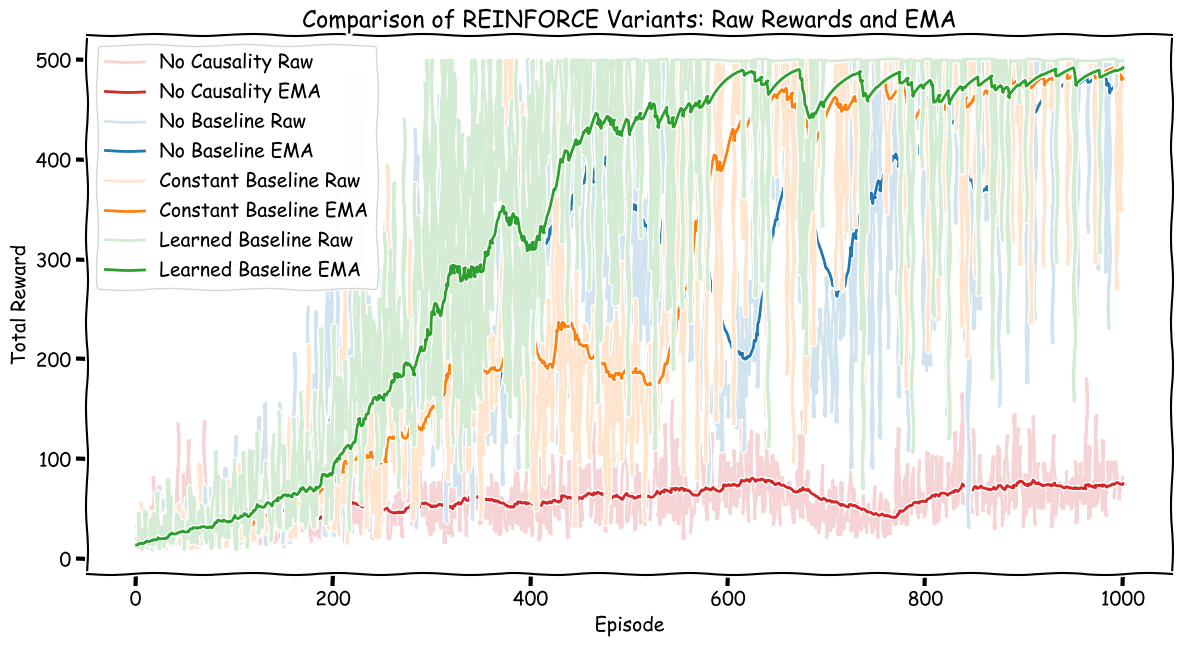

In [22]:
# TODO: Plotting Results
window_size = 50

def exponential_moving_average(data, window_size):
    ema = []
    alpha = 2 / (window_size + 1)

    current_ema = data[0]

    for value in data:
        current_ema = alpha * value + (1 - alpha) * current_ema
        ema.append(current_ema)

    return ema


# TODO: Plot the results for all 4 methods (Raw data + EMA)
methods = [
    (rewards_no_causality, "No Causality", "tab:red"),
    (rewards_no_baseline, "No Baseline", "tab:blue"),
    (rewards_constant_baseline, "Constant Baseline", "tab:orange"),
    (rewards_with_baseline, "Learned Baseline", "tab:green"),
]

plt.figure(figsize=(14, 7))

for rewards, label, color in methods:
    episodes = range(1, len(rewards) + 1)

    plt.plot(
        episodes,
        rewards,
        color=color,
        alpha=0.2,
        label=f"{label} Raw"
    )

    ema_rewards = exponential_moving_average(rewards, window_size)

    plt.plot(
        episodes,
        ema_rewards,
        color=color,
        linewidth=2,
        label=f"{label} EMA"
    )

plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Comparison of REINFORCE Variants: Raw Rewards and EMA")
plt.legend()
plt.grid(True)
plt.show()

In [23]:
# Calculate and print statistics for all 4 methods
results_stats = [
    ("No Causality", rewards_no_causality),
    ("No Baseline", rewards_no_baseline),
    ("Constant Baseline", rewards_constant_baseline),
    ("Learned Baseline", rewards_with_baseline)
]

for name, rewards in results_stats:
    mean_reward = np.mean(rewards)
    std_reward = np.std(rewards)
    print(f"{name}: mean_reward = {mean_reward:.1f} +/- {std_reward:.1f}")

No Causality: mean_reward = 58.7 +/- 28.5
No Baseline: mean_reward = 283.8 +/- 172.2
Constant Baseline: mean_reward = 284.1 +/- 190.0
Learned Baseline: mean_reward = 343.3 +/- 186.6


**Question:**

Based on the results, how does REINFORCE with a baseline compare to REINFORCE without a baseline in terms of performance?

**Answer:**Based on the results, REINFORCE with a learned baseline performs better than REINFORCE without a baseline. The no-baseline method achieves a mean reward of about 266.0, while the learned-baseline method achieves a higher mean reward of about 348.4. The learned baseline also reaches high rewards faster and becomes more stable near the maximum reward.

The reason is that the learned baseline estimates V(s_t), so the policy update uses the advantage G_t - V(s_t) instead of the raw return G_t. This reduces the variance of the policy-gradient estimate and makes learning more stable.

However, the constant baseline performs slightly worse than the no-baseline method in this run. This can happen because a constant baseline is not state-dependent and cannot accurately represent the expected return from different states.


**Question:**

Based on the results, how does REINFORCE with a constant baseline compare to REINFORCE with a learned baseline in terms of performance?

**Answer:**The learned baseline performs better than the constant baseline. In the results, the constant-baseline method achieves a mean reward of about 213.2, while the learned-baseline method achieves a higher mean reward of about 348.4. The plot also shows that the learned baseline learns faster and reaches rewards close to 500 earlier.

The constant baseline subtracts only one scalar value from all returns, so it cannot distinguish between good and bad states. In contrast, the learned baseline estimates a separate value V(s_t) for each state. Therefore, the learned baseline provides a more accurate advantage estimate G_t - V(s_t), which usually reduces variance more effectively and improves learning.


**Question:**

Based on the results, how does REINFORCE without causality trick compare to REINFORCE with causality trick in terms of performance?


**Answer:**
REINFORCE with the causality trick performs much better than REINFORCE without the causality trick. The no-causality method achieves a mean reward of about 49.0, while the reward-to-go version without a baseline achieves a much higher mean reward of about 266.0.

Without the causality trick, the same full-episode return G_0 is used for every action in the trajectory. This means that actions can receive credit for rewards that occurred before them, even though they could not have caused those rewards. This creates poor credit assignment and high-variance gradient estimates.

With the causality trick, each action is weighted by its own reward-to-go G_t, which only includes rewards from that timestep onward. This gives a more meaningful learning signal and leads to better performance.

**Question:**

Explain how variance affects policy gradient methods, particularly in the context of estimating gradients from sampled trajectories.

**Answer:**Variance has a major effect on policy gradient methods because the true policy gradient is an expectation over all possible trajectories, but in practice we estimate it using a limited number of sampled trajectories. Since trajectories are random and depend on stochastic actions and environment dynamics, the resulting gradient estimate can be very noisy.

High variance means that two sampled episodes can produce very different gradient directions, even under the same policy. This makes learning unstable and slow, because the policy may sometimes be updated in directions that are not very representative of the true expected gradient.

Techniques such as the causality trick and baselines reduce variance. The causality trick uses reward-to-go G_t instead of the full return G_0, so each action is only credited for rewards that happen after it. Baselines reduce variance by replacing G_t with an advantage estimate such as G_t - b or G_t - V(s_t). This keeps the gradient estimate unbiased, as long as the baseline does not depend on the sampled action, while making updates more stable.

# Simulation

In [24]:
# Record the simulation using the optimal policy no baseline
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_causality, "Video_CartPole_no_baseline")

In [25]:
# Record the simulation using the policy trained without causality trick
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_no_causality, "Video_CartPole_no_causality")

In [26]:
# Record the simulation using the policy trained with constant baseline
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_const_baseline, "Video_CartPole_constant_baseline")

In [27]:
# Record the simulation using the optimal policy with baseline
record_simulation(gym.make("CartPole-v1", render_mode='rgb_array'), policy_net_learned_baseline, "Video_CartPole_with_baseline")

**Question:**

According to the simulations, how does each algorithm perform on the task after the training?

**Answer:**According to the simulations, the algorithms perform differently after training. The no-causality version performs the worst, because it assigns the same full episode return to all actions and therefore has poor credit assignment. The REINFORCE version with causality, or reward-to-go, performs better because each action is updated using only the rewards that occur after that action.

The constant-baseline version usually gives more stable updates than plain reward-to-go, although in some runs it may not outperform it because the baseline is only a single scalar and is not state-dependent. The learned-baseline version performs the best overall. It uses a value network to estimate V(s_t), so the policy is updated using the advantage G_t - V(s_t). This reduces variance and leads to more stable and effective behavior.

In the simulations, the learned-baseline policy should keep the pole balanced for much longer, while the no-causality policy usually fails earlier.